# ORPO Fine-Tuning: Meta-Llama-3-8B-Instruct

**ORPO (Odds Ratio Preference Optimization)** is a preference alignment technique that combines SFT and preference optimization in a single training step - no reference model needed!

**Dataset Format Required:**
- `prompt`: The user question/instruction
- `chosen`: The preferred/correct response
- `rejected`: The non-preferred/incorrect response

**Key Advantages of ORPO:**
- Single-stage training (vs DPO's two-stage)
- No reference model needed (saves ~50% GPU memory)
- Often achieves better alignment than DPO

## 1. Environment Setup & Dependencies

In [1]:
# ============================================================================
# STEP 1: Install all required packages (KERNEL-SAFE VERSION)
# ============================================================================
# Note: ORPO requires trl>=0.8.0 for ORPOTrainer support

# Downgrade NumPy to prevent compatibility issues
!python -m pip install "numpy<2.0" --upgrade -q > /dev/null 2>&1

# Ensure clean pip and build tools
!python -m pip install pip==23.3.1 --upgrade -q > /dev/null 2>&1
!python -m pip install wheel setuptools --upgrade -q > /dev/null 2>&1

# Install PyTorch 2.1.0 with CUDA 11.8
!python -m pip install \
    torch==2.1.0+cu118 \
    torchvision==0.16.0+cu118 \
    torchaudio==2.1.0 \
    --index-url https://download.pytorch.org/whl/cu118 \
    -q > /dev/null 2>&1

# Install ML / training packages
# IMPORTANT: trl>=0.8.0 is required for ORPOTrainer
# Using transformers 4.44.2 for better Llama 3 RoPE support
!python -m pip install -q \
    transformers==4.44.2 \
    peft==0.12.0 \
    accelerate==0.33.0 \
    datasets==2.20.0 \
    scipy==1.12.0 \
    trl==0.9.6 \
    hf_transfer==0.1.6 \
    wandb==0.17.0 \
    matplotlib

# Install flash-attention for memory-efficient attention
!python -m pip install flash-attn==2.5.8 --no-build-isolation -q 

!pip install rich


[notice] A new release of pip is available: 23.3.1 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip

[notice] A new release of pip is available: 23.3.1 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.4/243.4 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.3/87.3 kB 29.6 MB/s eta 0:00:00

[notice] A new release of pip is available: 23.3.1 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip


In [2]:
import transformers
print(transformers.__version__)

4.44.2


In [2]:
!python -m transformers env

/usr/bin/python: No module named transformers.__main__; 'transformers' is a package and cannot be directly executed


## 2. Authentication & Logging Setup

In [3]:
# ============================================================================
# STEP 2: Import libraries and authenticate with HuggingFace & Weights & Biases
# ============================================================================

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
import os
import wandb

# Login to HuggingFace Hub (required for gated models like Llama)
from huggingface_hub import login
login(token=os.environ['HF_TOKEN'])

# Initialize Weights & Biases for experiment tracking
wandb.login(key=os.environ['WANDB_API_KEY'])
run = wandb.init(
    project='orpo_finetune_DeepSeek-R1-Distill-Llama-8B',  # New project for DeepSeek
    job_type='training',
    anonymous='allow'
)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
wandb: Currently logged in as: radhakrishna5a99 (radhakrishna5a99-innomatics-research-labs). Use `wandb login --relogin` to force relogin
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


In [4]:
# ============================================================================
# STEP 3: Import all required modules for ORPO training
# ============================================================================

from datasets import Dataset, load_dataset
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import TextStreamer
from trl import ORPOConfig, ORPOTrainer  # ORPO-specific imports
import torch
import gc

## 3. Model Configuration

In [5]:
# ============================================================================
# STEP 4: Define model and cache paths
# ============================================================================

model_id = "deepseek-ai/DeepSeek-R1-Distill-Llama-8B"  # Base model to fine-tune
cache_dir = "./model-cache"  # Local cache for downloaded model weights

In [6]:
# ============================================================================
# STEP 5: Device map generator for multi-GPU distribution
# ============================================================================
# This function distributes model layers across available GPUs evenly
# Useful when model is too large for single GPU
# DeepSeek-R1-Distill-Llama-8B has 32 transformer layers

def generate_device_map(num_layers: int, num_gpus: int) -> dict:
    """
    Generate a device map to distribute model layers across GPUs.
    
    Args:
        num_layers: Number of transformer layers in the model (32 for Llama-3-8B)
        num_gpus: Number of GPUs available
    
    Returns:
        dict: Mapping of layer names to GPU indices
    """
    device_map = {}
    layers_per_gpu = num_layers // num_gpus
    remainder = num_layers % num_gpus

    layer_id = 0
    for gpu in range(num_gpus):
        # Distribute remainder layers to first GPUs
        this_gpu_layer_count = layers_per_gpu + (1 if gpu < remainder else 0)
        for _ in range(this_gpu_layer_count):
            device_map[f"model.layers.{layer_id}"] = gpu
            layer_id += 1

    # Place embedding and output layers
    device_map["model.embed_tokens"] = 0          # Input embeddings on first GPU
    device_map["model.norm"] = num_gpus - 1       # Final norm on last GPU
    device_map["lm_head"] = num_gpus - 1          # Output head on last GPU

    return device_map

## 4. Load Base Model & Tokenizer

In [7]:
# ============================================================================
# STEP 6: Load the base model
# ============================================================================
# Using bfloat16 for memory efficiency on Ampere+ GPUs
# Flash Attention 2 reduces memory usage and speeds up training

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map=generate_device_map(32, 1),  # 32 layers for Llama-3-8B, 1 GPU
    torch_dtype=torch.bfloat16,             # Memory-efficient dtype for Ampere GPUs
    attn_implementation="flash_attention_2", # Faster & less memory
    cache_dir=cache_dir,
    trust_remote_code=True
)

# Load tokenizer with fast implementation
tokenizer = AutoTokenizer.from_pretrained(
    model_id,
    use_fast=True,
    trust_remote_code=True
)

config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-000002.safetensors:   0%|          | 0.00/8.67G [00:00<?, ?B/s]

model-00002-of-000002.safetensors:   0%|          | 0.00/7.39G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [8]:
# ============================================================================
# STEP 7: Test the base model before fine-tuning
# ============================================================================
# This helps establish a baseline for comparison after ORPO training

import re

def evaluate(question, model, tokenizer):
    """
    Generate a response from the model for a given question.
    Updated for DeepSeek-R1-Distill-Llama-8B format.
    
    DeepSeek-R1 Key Differences:
    - Uses <｜User｜> and <｜Assistant｜> special tokens (unicode characters!)
    - NO system prompt support - include instructions in user message
    - Recommends temperature 0.6, top_p 0.95
    - May output <think>...</think> reasoning blocks
    """
    
    # Option 1: Use tokenizer's chat template (RECOMMENDED - simpler)
    messages = [
        {"role": "user", "content": question}
    ]
    
    formatted_prompt = tokenizer.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True
    )
    
    # Option 2: Manual format (if tokenizer template doesn't work)
    # formatted_prompt = f"<｜User｜>{question}<｜Assistant｜>"
    
    inputs = tokenizer([formatted_prompt], return_tensors="pt").to("cuda")
    
    # DeepSeek recommended generation settings
    outputs = model.generate(
        **inputs,
        max_new_tokens=500,
        temperature=0.6,          # DeepSeek recommended: 0.5-0.7
        top_p=0.95,               # DeepSeek recommended
        do_sample=True,           # Required when using temperature
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    
    # Decode response
    generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
    
    # Optional: Remove <think>...</think> reasoning blocks if you only want final answer
    # generated_text = re.sub(r'<think>.*?</think>', '', generated_text, flags=re.DOTALL)
    
    print(generated_text)
    return generated_text

test_question = 'According to HDFC ERGO Optima Restore, If I got diagnosed with a critical illness, can I get a second opinion from another doctor, which can be covered by insurance?'
print("=" * 50)
print("BASE MODEL RESPONSE (before ORPO training):")
print("=" * 50)
evaluate(test_question, model, tokenizer)

BASE MODEL RESPONSE (before ORPO training):
<｜User｜>According to HDFC ERGO Optima Restore, If I got diagnosed with a critical illness, can I get a second opinion from another doctor, which can be covered by insurance?<｜Assistant｜><think>
Okay, so I just got this message about HDFC ERGO Optima Restore and whether I can get a second opinion if I'm diagnosed with a critical illness. I'm a bit confused about how insurance works, especially when it comes to getting a second opinion. Let me try to break this down.

First, I remember that HDFC ERGO Optima Restore is a kind of health insurance policy. I think it's a critical illness cover, which means it provides a lump sum payment if I'm diagnosed with a specified critical illness. But the user is asking if they can get a second opinion from another doctor and if that's covered by their insurance.

So, the main question is about whether getting a second opinion is covered. I know that sometimes insurance policies have certain terms and condit

"<｜User｜>According to HDFC ERGO Optima Restore, If I got diagnosed with a critical illness, can I get a second opinion from another doctor, which can be covered by insurance?<｜Assistant｜><think>\nOkay, so I just got this message about HDFC ERGO Optima Restore and whether I can get a second opinion if I'm diagnosed with a critical illness. I'm a bit confused about how insurance works, especially when it comes to getting a second opinion. Let me try to break this down.\n\nFirst, I remember that HDFC ERGO Optima Restore is a kind of health insurance policy. I think it's a critical illness cover, which means it provides a lump sum payment if I'm diagnosed with a specified critical illness. But the user is asking if they can get a second opinion from another doctor and if that's covered by their insurance.\n\nSo, the main question is about whether getting a second opinion is covered. I know that sometimes insurance policies have certain terms and conditions. I should check if the policy all

In [9]:
# ============================================================================
# STEP 8: Verify no parameters are on CPU/meta device
# ============================================================================
# Parameters on 'meta' device indicate incomplete model loading

print("Checking for parameters on meta device...")
meta_params = []
for n, p in model.named_parameters():
    if p.device.type == "meta":
        meta_params.append(n)
        
if meta_params:
    print(f"WARNING: {len(meta_params)} parameters on meta device!")
    for p in meta_params[:5]:  # Print first 5
        print(f"  - {p}")
else:
    print("✓ All parameters loaded correctly on GPU")

Checking for parameters on meta device...
✓ All parameters loaded correctly on GPU


## 5. LoRA Configuration

In [10]:
# ============================================================================
# STEP 9: Helper function to count trainable parameters
# ============================================================================

def print_trainable_parameters(model):
    """
    Print summary of trainable vs frozen parameters.
    Useful for verifying LoRA is applied correctly.
    """
    trainable_params = 0
    non_trainable_params = 0
    all_params = 0

    for name, param in model.named_parameters():
        all_params += param.numel()
        if param.requires_grad:
            trainable_params += param.numel()
        else:
            non_trainable_params += param.numel()

    print(f"\n{'='*50}")
    print(f"Parameter Summary:")
    print(f"{'='*50}")
    print(f"  Trainable params:     {trainable_params:,}")
    print(f"  Non-trainable params: {non_trainable_params:,}")
    print(f"  Total params:         {all_params:,}")
    print(f"  Trainable %:          {100 * trainable_params / all_params:.4f}%")

print("BEFORE LoRA:")
print_trainable_parameters(model)

BEFORE LoRA:

Parameter Summary:
  Trainable params:     8,030,261,248
  Non-trainable params: 0
  Total params:         8,030,261,248
  Trainable %:          100.0000%


In [11]:
# ============================================================================
# STEP 10: Configure LoRA (Low-Rank Adaptation)
# ============================================================================
# LoRA adds small trainable matrices to attention/MLP layers
# This dramatically reduces memory usage and training time

peft_config = LoraConfig(
    r=16,                    # Rank of LoRA matrices (higher = more capacity, more memory)
    lora_alpha=32,           # Scaling factor (typically 2x rank)
    target_modules=[         # Which layers to apply LoRA to
        "q_proj",            # Query projection in attention
        "k_proj",            # Key projection in attention
        "v_proj",            # Value projection in attention  
        "o_proj",            # Output projection in attention
        "gate_proj",         # MLP gate projection
        "up_proj",           # MLP up projection
        "down_proj",         # MLP down projection
    ],
    lora_dropout=0.05,       # Dropout for regularization (lower for ORPO)
    bias="none",             # Don't train bias terms
    task_type="CAUSAL_LM",   # Task type for causal language modeling
)

# Apply LoRA to the model
model = get_peft_model(model, peft_config)

print("AFTER LoRA:")
print_trainable_parameters(model)

AFTER LoRA:

Parameter Summary:
  Trainable params:     41,943,040
  Non-trainable params: 8,030,261,248
  Total params:         8,072,204,288
  Trainable %:          0.5196%


## 6. Tokenizer Configuration

In [12]:
# ============================================================================
# STEP 11: Configure padding token
# ============================================================================
# Check what special tokens DeepSeek has available

print(f"Available special tokens: {tokenizer.special_tokens_map}")
print(f"EOS token: {tokenizer.eos_token} (ID: {tokenizer.eos_token_id})")
print(f"BOS token: {tokenizer.bos_token} (ID: {tokenizer.bos_token_id})")

if tokenizer.pad_token is None:
    if '<pad>' in tokenizer.get_vocab():
        print('Using <pad> token for padding')
        tokenizer.pad_token = '<pad>'
    elif '<|pad|>' in tokenizer.get_vocab():
        print('Using <|pad|> token for padding')
        tokenizer.pad_token = '<|pad|>'
    elif '<unk>' in tokenizer.get_vocab():
        print('Using <unk> token for padding')
        tokenizer.pad_token = '<unk>'
    else:
        # Fallback: use EOS token
        print(f'Using EOS token ({tokenizer.eos_token}) for padding')
        tokenizer.pad_token = tokenizer.eos_token
else:
    print(f'Pad token already set: {tokenizer.pad_token}')

# Set padding side to right for causal LM
tokenizer.padding_side = "right"

Available special tokens: {'bos_token': '<｜begin▁of▁sentence｜>', 'eos_token': '<｜end▁of▁sentence｜>', 'pad_token': '<｜end▁of▁sentence｜>'}
EOS token: <｜end▁of▁sentence｜> (ID: 128001)
BOS token: <｜begin▁of▁sentence｜> (ID: 128000)
Pad token already set: <｜end▁of▁sentence｜>


## 7. Load & Prepare Dataset for ORPO

In [13]:
# ============================================================================
# STEP 12: Load your preference dataset
# ============================================================================
# Your dataset should have 3 columns:
#   - question: The user's question/prompt
#   - chosen: The preferred/correct response
#   - rejected: The non-preferred/incorrect response

from datasets import load_dataset

# TODO: Replace with your actual dataset path
dataset_name = "agi123/optima_restore_ha"

data = load_dataset(dataset_name)

print(f"Dataset loaded: {dataset_name}")
print(f"Train samples: {len(data['train'])}")
print(f"Columns: {data['train'].column_names}")

Generating train split:   0%|          | 0/2115 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/30 [00:00<?, ? examples/s]

Dataset loaded: agi123/optima_restore_ha
Train samples: 2115
Columns: ['question', 'answer', 'rejected']


In [14]:
# ============================================================================
# STEP 13: Format dataset for ORPO training
# ============================================================================
# ORPOTrainer expects a specific format with 'prompt', 'chosen', 'rejected' keys
# Each should be a list of message dictionaries for chat models

def format_for_orpo(example):
    """
    Convert dataset row to ORPO format.
    
    ORPO expects:
    - prompt: List of message dicts (the conversation context)
    - chosen: List of message dicts (preferred response)
    - rejected: List of message dicts (non-preferred response)
    """
    return {
        # The prompt/question as a user message
        "prompt": [
            {"role": "user", "content": example["question"]}
        ],
        # The preferred (correct) response
        "chosen": [
            {"role": "assistant", "content": example["answer"]}
        ],
        # The rejected (incorrect) response
        "rejected": [
            {"role": "assistant", "content": example["rejected"]}
        ]
    }

# Apply formatting to entire dataset
print("Formatting dataset for ORPO...")
formatted_dataset = data['train'].map(
    format_for_orpo,
    remove_columns=data['train'].column_names  # Remove original columns
)

print(f"\nFormatted dataset columns: {formatted_dataset.column_names}")
print(f"Total samples: {len(formatted_dataset)}")

Formatting dataset for ORPO...


Map:   0%|          | 0/2115 [00:00<?, ? examples/s]


Formatted dataset columns: ['rejected', 'prompt', 'chosen']
Total samples: 2115


In [15]:
# ============================================================================
# STEP 14: Split into train and evaluation sets
# ============================================================================
# We'll use 95% for training and 5% for evaluation

split_dataset = formatted_dataset.train_test_split(test_size=0.05, seed=42)

train_dataset = split_dataset['train']
eval_dataset = split_dataset['test']

print(f"Training samples: {len(train_dataset)}")
print(f"Evaluation samples: {len(eval_dataset)}")

Training samples: 2009
Evaluation samples: 106


In [16]:
# ============================================================================
# STEP 15: Inspect a sample to verify formatting
# ============================================================================

print("Sample from training dataset:")
print("=" * 50)
sample = train_dataset[0]

print(f"\nPROMPT:")
print(f"  {sample['prompt']}")

print(f"\nCHOSEN (preferred response):")
print(f"  {sample['chosen'][0]['content'][:200]}...")

print(f"\nREJECTED (non-preferred response):")
print(f"  {sample['rejected'][0]['content'][:200]}...")

Sample from training dataset:

PROMPT:
  [{'content': 'What is the discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore policy  for 3 year policy?', 'role': 'user'}]

CHOSEN (preferred response):
  The discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore 3 year policy is 0.1667%....

REJECTED (non-preferred response):
  The discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore policy is 75%....


## 8. Training Configuration

In [17]:
# ============================================================================
# STEP 16: Define training hyperparameters
# ============================================================================

# Model naming
model_name = model_id.split("/")[-1]
dataset_short_name = dataset_name.split("/")[-1]

model_name = model_id.split("/")[-1]
dataset_short_name = dataset_name.split("/")[-1]

# Training hyperparameters
epochs = 5
batch_size = 2                # May need to reduce if OOM (DeepSeek can use more memory)
grad_accum = 1
learning_rate = 5e-6          # Can try 2e-6 to 8e-6 for DeepSeek
max_length = 1024             # DeepSeek supports up to 32K, but keep 1024 for training efficiency
max_prompt_length = 512
beta = 0.1                    # ORPO beta - start with same value

warmup_ratio = 0.1

# Output paths - Updated tag for DeepSeek
fine_tune_tag = 'orpo_health_insurance_deepseek'
save_dir = f'./results/{model_name}_{dataset_short_name}_{epochs}_epochs_orpo-{fine_tune_tag}'

print(f"Output directory: {save_dir}")
print(f"Effective batch size: {batch_size * grad_accum}")

Output directory: ./results/DeepSeek-R1-Distill-Llama-8B_optima_restore_ha_5_epochs_orpo-orpo_health_insurance_deepseek
Effective batch size: 2


In [18]:
# ============================================================================
# STEP 17: Custom logging callback for detailed tracking
# ============================================================================

import transformers
import os

class ORPOLoggingCallback(transformers.TrainerCallback):
    """
    Custom callback to log ORPO-specific metrics to a file.
    ORPO logs additional metrics like:
    - rewards/chosen: Log probability of chosen response
    - rewards/rejected: Log probability of rejected response  
    - rewards/margins: Difference between chosen and rejected
    - log_odds_ratio: The odds ratio used in ORPO loss
    """
    def __init__(self, log_file_path, save_dir):
        self.log_file_path = log_file_path
        self.save_dir = save_dir

    def on_log(self, args, state, control, model=None, logs=None, **kwargs):
        with open(self.log_file_path, 'a') as f:
            # Log training loss
            if 'loss' in logs:
                f.write(f"Step: {state.global_step}, Training Loss: {logs['loss']:.4f}\n")
            
            # Log eval loss
            if 'eval_loss' in logs:
                f.write(f"Step: {state.global_step}, Eval Loss: {logs['eval_loss']:.4f}\n")
            
            # Log ORPO-specific metrics
            if 'rewards/margins' in logs:
                f.write(f"Step: {state.global_step}, Reward Margin: {logs['rewards/margins']:.4f}\n")
            
            f.flush()

        # Save checkpoint with trainable params
        if state.global_step % int(args.save_steps) == 0 and state.global_step > 0:
            checkpoint_dir = os.path.join(args.output_dir, f"checkpoint-{state.global_step}")
            os.makedirs(checkpoint_dir, exist_ok=True)
            
            # Save trainable parameters
            current_trainable_params = {n: p.data for n, p in model.named_parameters() if p.requires_grad}
            file_path = os.path.join(checkpoint_dir, "trainable_params.bin")
            torch.save(current_trainable_params, file_path)

# Initialize callback
os.makedirs(cache_dir, exist_ok=True)
log_file_path = os.path.join(cache_dir, "orpo_training_logs.txt")
logging_callback = ORPOLoggingCallback(log_file_path, save_dir)

print(f"Logging to: {log_file_path}")

Logging to: ./model-cache/orpo_training_logs.txt


## 9. Initialize ORPO Trainer

In [19]:
# ============================================================================
# STEP 18: Configure ORPOTrainer
# ============================================================================
# ORPO combines SFT loss with odds ratio preference optimization
# Loss = SFT_loss + beta * ORPO_loss

orpo_config = ORPOConfig(
    # Output configuration
    output_dir=save_dir,
    
    # Training duration
    num_train_epochs=epochs,
    # max_steps=10,  # Uncomment for quick test run
    
    # Batch size configuration
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    gradient_accumulation_steps=grad_accum,
    
    # Learning rate configuration
    learning_rate=learning_rate,
    lr_scheduler_type="cosine",       # Cosine decay schedule
    warmup_ratio=warmup_ratio,         # Gradual warmup at start
    
    # ORPO-specific parameters
    beta=beta,                         # Preference optimization strength
    max_length=max_length,             # Max total sequence length
    max_prompt_length=max_prompt_length,  # Max prompt length
    
    # Precision and optimization
    bf16=True,                         # Use bfloat16 for Ampere+ GPUs
    # fp16=True,                       # Use for older GPUs (V100, etc.)
    optim="adamw_torch",               # Optimizer
    max_grad_norm=0.3,                 # Gradient clipping
    
    # Evaluation configuration
    eval_strategy="steps",
    eval_steps=0.1,                    # Evaluate every 10% of training
    do_eval=True,
    
    # Logging configuration
    logging_steps=1,                   # Log every step
    log_level="info",
    report_to="wandb",                 # Log to Weights & Biases
    run_name=f"orpo-deepseek-r1-{fine_tune_tag}",
    
    # Checkpointing
    save_strategy="steps",
    save_steps=200,                    # Save checkpoint every 200 steps
    save_total_limit=3,                # Keep only 3 most recent checkpoints
    
    # Hub configuration (optional)
    hub_private_repo=True,
    
    # Reproducibility
    seed=42,
)

In [20]:
# Check the structure of your dataset
print(train_dataset[0])
print()
print(f"Type of prompt: {type(train_dataset[0]['prompt'])}")
print(f"Type of chosen: {type(train_dataset[0]['chosen'])}")
print(f"Type of rejected: {type(train_dataset[0]['rejected'])}")

{'rejected': [{'content': 'The discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore policy is 75%.', 'role': 'assistant'}], 'prompt': [{'content': 'What is the discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore policy  for 3 year policy?', 'role': 'user'}], 'chosen': [{'content': 'The discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore 3 year policy is 0.1667%.', 'role': 'assistant'}]}

Type of prompt: <class 'list'>
Type of chosen: <class 'list'>
Type of rejected: <class 'list'>


In [21]:
def convert_chat_to_string(example):
    """Convert chat format to plain string format for ORPOTrainer"""
    # Extract content from the message list
    example['prompt'] = example['prompt'][0]['content']
    example['chosen'] = example['chosen'][0]['content']
    example['rejected'] = example['rejected'][0]['content']
    return example

# Apply the conversion
train_dataset = train_dataset.map(convert_chat_to_string)
eval_dataset = eval_dataset.map(convert_chat_to_string)

# Verify the fix
print("After conversion:")
print(train_dataset[0])
print(f"\nType of prompt: {type(train_dataset[0]['prompt'])}")

Map:   0%|          | 0/2009 [00:00<?, ? examples/s]

Map:   0%|          | 0/106 [00:00<?, ? examples/s]

After conversion:
{'rejected': 'The discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore policy is 75%.', 'prompt': 'What is the discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore policy  for 3 year policy?', 'chosen': 'The discount percentage for the time interval of 811-900 days for the step count range of 5001 to 8000 in the HDFC ERGO Optima Restore 3 year policy is 0.1667%.'}

Type of prompt: <class 'str'>


In [22]:
# ============================================================================
# STEP 19: Initialize the ORPOTrainer
# ============================================================================
# Note: Unlike DPO, ORPO does NOT require a reference model!
# This saves ~50% GPU memory compared to DPO

trainer = ORPOTrainer(
    model=model,                       # The LoRA-wrapped model
    args=orpo_config,                  # Training configuration
    train_dataset=train_dataset,       # Training data
    eval_dataset=eval_dataset,         # Evaluation data
    tokenizer=tokenizer,        # Tokenizer for processing
    peft_config=peft_config,           # LoRA configuration
    callbacks=[logging_callback],      # Custom logging callback
)

print("\n" + "="*50)
print("ORPO Trainer initialized successfully!")
print("="*50)
print(f"Training samples: {len(train_dataset)}")
print(f"Evaluation samples: {len(eval_dataset)}")
print(f"Epochs: {epochs}")
print(f"Effective batch size: {batch_size * grad_accum}")
print(f"ORPO beta: {beta}")

/usr/local/lib/python3.11/dist-packages/trl/trainer/orpo_trainer.py:247: UserWarning: When using DPODataCollatorWithPadding, you should set `remove_unused_columns=False` in your TrainingArguments we have set it for you, but you should do it yourself in the future.
  warnings.warn(


Map:   0%|          | 0/2009 [00:00<?, ? examples/s]

Map:   0%|          | 0/106 [00:00<?, ? examples/s]

Using auto half precision backend



ORPO Trainer initialized successfully!
Training samples: 2009
Evaluation samples: 106
Epochs: 5
Effective batch size: 2
ORPO beta: 0.1


## 10. Train the Model

In [23]:
# ============================================================================
# STEP 20: Start ORPO training!
# ============================================================================
# Monitor these metrics during training:
#   - loss: Total ORPO loss (SFT + preference)
#   - rewards/chosen: Should increase (model prefers chosen)
#   - rewards/rejected: Should decrease or stay stable
#   - rewards/margins: Should increase (bigger gap = better alignment)

print("\n" + "="*50)
print("Starting ORPO Training...")
print("="*50)

trainer.train()

print("\n" + "="*50)
print("Training Complete!")
print("="*50)


Starting ORPO Training...


***** Running training *****
  Num examples = 2,009
  Num Epochs = 5
  Instantaneous batch size per device = 2
  Total train batch size (w. parallel, distributed & accumulation) = 2
  Gradient Accumulation steps = 1
  Total optimization steps = 5,025
  Number of trainable parameters = 41,943,040
Automatic Weights & Biases logging enabled, to disable set os.environ["WANDB_DISABLED"] = "true"
Could not estimate the number of tokens of the input, floating-point operations will not be computed


Step,Training Loss,Validation Loss,Runtime,Samples Per Second,Steps Per Second,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/rejected,Logps/chosen,Logits/rejected,Logits/chosen,Nll Loss,Log Odds Ratio,Log Odds Chosen
503,1.430700,1.600657,6.684000,15.859000,7.929000,-0.121542,-0.174278,0.811321,0.052736,-1.742782,-1.215422,-2.407339,-2.336464,1.554906,-0.457509,0.835248
1006,1.516100,1.173078,6.821500,15.539000,7.769000,-0.098644,-0.177364,0.952830,0.078720,-1.773643,-0.986443,-2.291430,-2.222081,1.138925,-0.341531,1.295349
1509,0.993500,1.019228,6.619100,16.014000,8.007000,-0.086780,-0.191593,0.981132,0.104813,-1.915934,-0.867801,-2.268251,-2.199258,0.993628,-0.255994,1.737518
2012,0.797200,0.928697,6.815100,15.554000,7.777000,-0.078656,-0.199905,0.981132,0.121249,-1.999054,-0.786559,-2.272497,-2.201373,0.907571,-0.211257,2.068013
2515,0.841300,0.874914,6.741000,15.725000,7.862000,-0.073493,-0.213429,0.990566,0.139936,-2.134288,-0.734930,-2.256295,-2.183079,0.857288,-0.176259,2.407408
3018,0.616000,0.817841,7.202000,14.718000,7.359000,-0.067584,-0.221460,0.990566,0.153876,-2.214597,-0.675841,-2.258371,-2.182339,0.802714,-0.151268,2.624396
3521,0.803900,0.795249,7.189400,14.744000,7.372000,-0.064913,-0.231057,0.990566,0.166144,-2.310574,-0.649129,-2.231186,-2.152635,0.781569,-0.136808,2.868788
4024,0.475600,0.783043,6.720100,15.774000,7.887000,-0.063947,-0.235101,0.990566,0.171153,-2.351007,-0.639474,-2.236569,-2.157909,0.769930,-0.131128,2.943557
4527,0.504700,0.783496,6.610200,16.036000,8.018000,-0.063932,-0.241883,0.990566,0.177951,-2.418833,-0.639324,-2.220055,-2.139047,0.770828,-0.126680,3.064540


Saving model checkpoint to ./results/DeepSeek-R1-Distill-Llama-8B_optima_restore_ha_5_epochs_orpo-orpo_health_insurance_deepseek/checkpoint-200


config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--deepseek-ai--DeepSeek-R1-Distill-Llama-8B/snapshots/6a6f4aa4197940add57724a7707d069478df56b1/config.json
Model config LlamaConfig {
  "architectures": [
    "LlamaForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 128000,
  "eos_token_id": 128001,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 14336,
  "max_position_embeddings": 131072,
  "mlp_bias": false,
  "model_type": "llama",
  "num_attention_heads": 32,
  "num_hidden_layers": 32,
  "num_key_value_heads": 8,
  "pretraining_tp": 1,
  "rms_norm_eps": 1e-05,
  "rope_scaling": {
    "factor": 8.0,
    "high_freq_factor": 4.0,
    "low_freq_factor": 1.0,
    "original_max_position_embeddings": 8192,
    "rope_type": "llama3"
  },
  "rope_theta": 500000.0,
  "tie_word_embeddings": false,
  "torch_dtype": "bfloat16",
  "transformers_version": "4.44.2",
  "us


Training Complete!


## 11. Evaluate & Visualize Results

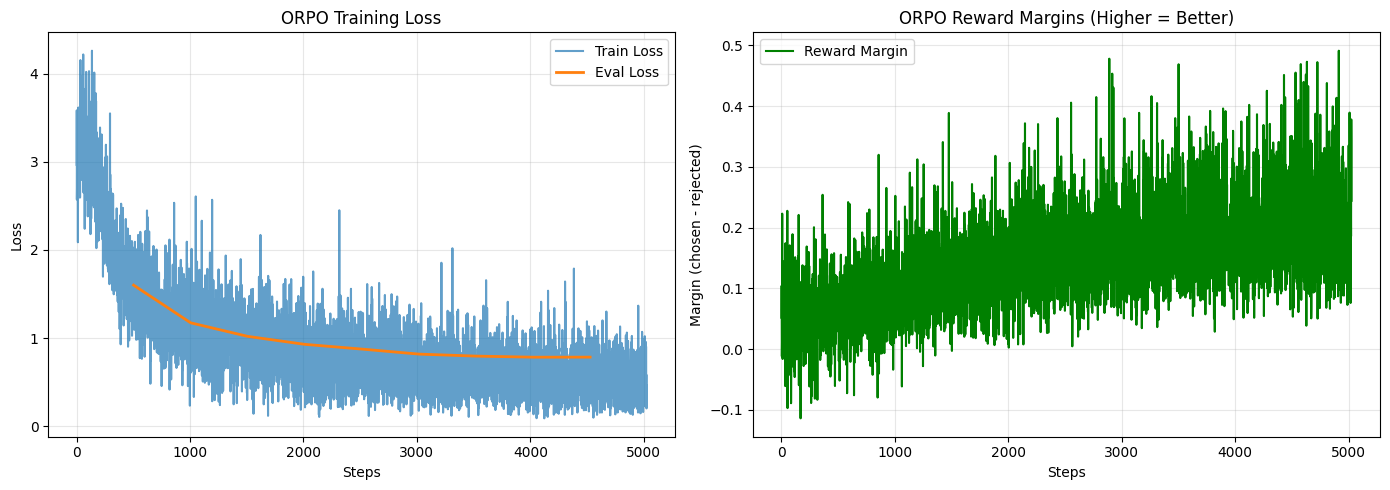

In [25]:
# ============================================================================
# STEP 21: Plot training curves
# ============================================================================

import matplotlib.pyplot as plt

# Extract metrics from training history
train_losses = []
eval_losses = []
train_steps = []
eval_steps = []
reward_margins = []
reward_margin_steps = []

for entry in trainer.state.log_history:
    if 'loss' in entry:
        train_losses.append(entry['loss'])
        train_steps.append(entry['step'])
    if 'eval_loss' in entry:
        eval_losses.append(entry['eval_loss'])
        eval_steps.append(entry['step'])
    if 'rewards/margins' in entry:
        reward_margins.append(entry['rewards/margins'])
        reward_margin_steps.append(entry['step'])

# Create figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training and Evaluation Loss
axes[0].plot(train_steps, train_losses, label='Train Loss', alpha=0.7)
axes[0].plot(eval_steps, eval_losses, label='Eval Loss', linewidth=2)
axes[0].set_xlabel('Steps')
axes[0].set_ylabel('Loss')
axes[0].set_title('ORPO Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Reward Margins (higher = better preference learning)
if reward_margins:
    axes[1].plot(reward_margin_steps, reward_margins, color='green', label='Reward Margin')
    axes[1].set_xlabel('Steps')
    axes[1].set_ylabel('Margin (chosen - rejected)')
    axes[1].set_title('ORPO Reward Margins (Higher = Better)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'training_curves.png'), dpi=150)
plt.show()

In [26]:
# ============================================================================
# STEP 22: Test the fine-tuned model
# ============================================================================
# Compare with the base model response from earlier

print("=" * 50)
print("FINE-TUNED MODEL RESPONSE (after ORPO training):")
print("=" * 50)
evaluate(test_question, model, tokenizer)

FINE-TUNED MODEL RESPONSE (after ORPO training):
<｜User｜>According to HDFC ERGO Optima Restore, If I got diagnosed with a critical illness, can I get a second opinion from another doctor, which can be covered by insurance?<｜Assistant｜><think>
According to the HDFC ERGO Optima Restore policy, if you are diagnosed with a critical illness, you can obtain a second opinion, but the insurer will not be obligated to make any payment unless the treating doctor confirms the diagnosis.


'<｜User｜>According to HDFC ERGO Optima Restore, If I got diagnosed with a critical illness, can I get a second opinion from another doctor, which can be covered by insurance?<｜Assistant｜><think>\nAccording to the HDFC ERGO Optima Restore policy, if you are diagnosed with a critical illness, you can obtain a second opinion, but the insurer will not be obligated to make any payment unless the treating doctor confirms the diagnosis.'

## 12. Save & Push Model

In [27]:
# ============================================================================
# STEP 23: Save the fine-tuned model locally
# ============================================================================

# Save the final model
trainer.save_model(save_dir)

# Save tokenizer alongside model
tokenizer.save_pretrained(save_dir)

print(f"\nModel saved to: {save_dir}")

Saving model checkpoint to ./results/DeepSeek-R1-Distill-Llama-8B_optima_restore_ha_5_epochs_orpo-orpo_health_insurance_deepseek
loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--deepseek-ai--DeepSeek-R1-Distill-Llama-8B/snapshots/6a6f4aa4197940add57724a7707d069478df56b1/config.json
Model config LlamaConfig {
  "architectures": [
    "LlamaForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 128000,
  "eos_token_id": 128001,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 14336,
  "max_position_embeddings": 131072,
  "mlp_bias": false,
  "model_type": "llama",
  "num_attention_heads": 32,
  "num_hidden_layers": 32,
  "num_key_value_heads": 8,
  "pretraining_tp": 1,
  "rms_norm_eps": 1e-05,
  "rope_scaling": {
    "factor": 8.0,
    "high_freq_factor": 4.0,
    "low_freq_factor": 1.0,
    "original_max_position_embeddings": 8192,
    "rope_type": "llama3"
  },


Model saved to: ./results/DeepSeek-R1-Distill-Llama-8B_optima_restore_ha_5_epochs_orpo-orpo_health_insurance_deepseek


In [ ]:
# ============================================================================
# STEP 24: Push to HuggingFace Hub 
# ============================================================================

# Define repository name
adapter_model = f"agi123/{model_name}-orpo-{fine_tune_tag}-epochs-{epochs}adapters"
print(f"Pushing to: {adapter_model}")

# Push LoRA adapters to Hub
model.push_to_hub(
    adapter_model,
    use_auth_token=True,
    max_shard_size="10GB",
    use_safetensors=True
)

# Push tokenizer
tokenizer.push_to_hub(adapter_model, use_auth_token=True)

print(f"\n✓ Model pushed to: https://huggingface.co/{adapter_model}")

Pushing to: agi123/DeepSeek-R1-Distill-Llama-8B-orpo-orpo_health_insurance_deepseek-epochs-5adapters


/usr/local/lib/python3.11/dist-packages/transformers/utils/hub.py:875: FutureWarning: The `use_auth_token` argument is deprecated and will be removed in v5 of Transformers. Please use `token` instead.
  warnings.warn(
loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--deepseek-ai--DeepSeek-R1-Distill-Llama-8B/snapshots/6a6f4aa4197940add57724a7707d069478df56b1/config.json
Model config LlamaConfig {
  "architectures": [
    "LlamaForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 128000,
  "eos_token_id": 128001,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 14336,
  "max_position_embeddings": 131072,
  "mlp_bias": false,
  "model_type": "llama",
  "num_attention_heads": 32,
  "num_hidden_layers": 32,
  "num_key_value_heads": 8,
  "pretraining_tp": 1,
  "rms_norm_eps": 1e-05,
  "rope_scaling": {
    "factor": 8.0,
    "high_freq_factor": 4.0,
    "low_freq_f

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

README.md: 0.00B [00:00, ?B/s]

tokenizer config file saved in /tmp/tmpxjb27nfa/tokenizer_config.json
Special tokens file saved in /tmp/tmpxjb27nfa/special_tokens_map.json
Uploading the following files to agi123/DeepSeek-R1-Distill-Llama-8B-orpo-orpo_health_insurance_deepseek-epochs-5adapters: tokenizer_config.json,special_tokens_map.json,tokenizer.json,README.md



✓ Model pushed to: https://huggingface.co/agi123/DeepSeek-R1-Distill-Llama-8B-orpo-orpo_health_insurance_deepseek-epochs-5adapters


In [ ]:
# https://huggingface.co/agi123/DeepSeek-R1-Distill-Llama-8B-orpo-orpo_health_insurance_deepseek-epochs-5adapters

## 13. Log Artifacts & Finish

In [29]:
# ============================================================================
# STEP 25: Log training artifacts to Weights & Biases
# ============================================================================

import json

artifact_name = f'orpo_run_{model_name}_{fine_tune_tag}'

# Create artifact directory
os.makedirs(f"artifacts/{artifact_name}", exist_ok=True)

# Save training arguments
training_args_dict = trainer.args.to_dict()
with open(f"artifacts/{artifact_name}/training_args.json", "w") as f:
    json.dump(training_args_dict, f, indent=4)

# Save evaluation results
eval_results = trainer.evaluate()
with open(f"artifacts/{artifact_name}/eval_results.json", "w") as f:
    json.dump(eval_results, f, indent=4)

# Save wandb run summary
summary_dict = dict(wandb.run.summary)
# Filter out non-serializable items
summary_dict = {k: v for k, v in summary_dict.items() if isinstance(v, (int, float, str, bool, list, dict))}
with open(f"artifacts/{artifact_name}/run_summary.json", "w") as f:
    json.dump(summary_dict, f, indent=4, default=str)

# Log to W&B
artifact = wandb.Artifact(
    name=f"{artifact_name}_config_and_results",
    type="training-config",
    description=f"ORPO training config and results for {model_name}",
)
artifact.add_dir(f"artifacts/{artifact_name}")
run.log_artifact(artifact)

# Finish the wandb run
run.finish()

print("\n" + "="*50)
print("ORPO Training Complete!")
print("="*50)
print(f"\nFinal eval loss: {eval_results.get('eval_loss', 'N/A')}")
print(f"Model saved to: {save_dir}")
print(f"Artifacts logged to W&B")


***** Running Evaluation *****
  Num examples = 106
  Batch size = 2


wandb: Adding directory to artifact (./artifacts/orpo_run_DeepSeek-R1-Distill-Llama-8B_orpo_health_insurance_deepseek)... Done. 0.0s


eval/log_odds_chosen,▁▂▄▅▆▇▇███
eval/log_odds_ratio,▁▃▅▆▇▇████
eval/logits/chosen,▁▅▆▆▆▆█▇██
eval/logits/rejected,▁▅▆▆▇▇█▇██
eval/logps/chosen,▁▄▅▆▇█████
eval/logps/rejected,██▆▅▄▃▂▂▁▁
eval/loss,█▄▃▂▂▁▁▁▁▁
eval/nll_loss,█▄▃▂▂▁▁▁▁▁
eval/rewards/accuracies,▁▇████████
eval/rewards/chosen,▁▄▅▆▇█████
eval/rewards/margins,▁▂▄▅▆▇▇███



ORPO Training Complete!

Final eval loss: 0.7821295857429504
Model saved to: ./results/DeepSeek-R1-Distill-Llama-8B_optima_restore_ha_5_epochs_orpo-orpo_health_insurance_deepseek
Artifacts logged to W&B


In [ ]:
# ============================================================================
# STEP 26: Cleanup (optional)
# ============================================================================
# Free up GPU memory

# del model
# del trainer
# gc.collect()
# torch.cuda.empty_cache()
# print("GPU memory cleared!")